Traffic Volume Prediction Model Comparison:
LinearRegression: MAE=337.16, RMSE=337.24, R2=-55.16
RidgeRegression: MAE=112.98, RMSE=155.40, R2=-10.93
RandomForest: MAE=123.55, RMSE=145.50, R2=-9.45


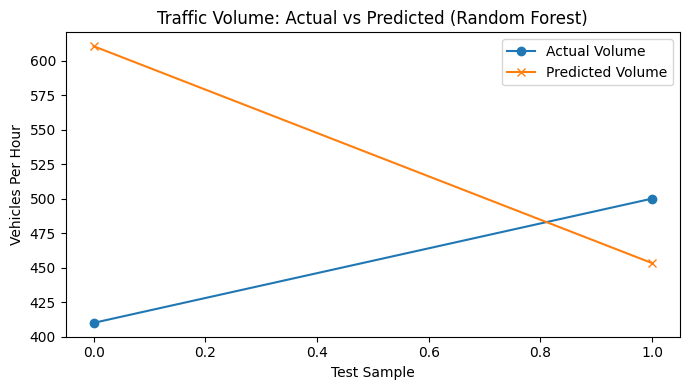

/tmp/ipython-input-156816331.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_names, y=rf_importances, palette='rocket')


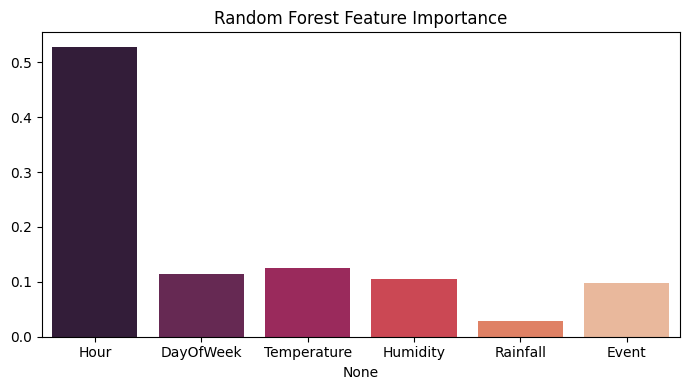


Predicted Traffic Volume for input sample: 617.10 vehicles/hour


In [1]:
# Traffic Volume Prediction Using Regression

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Synthetic sample traffic data (for demonstration)
data = pd.DataFrame({
    'Hour': [7, 8, 9, 10, 11, 17, 18, 19, 20, 21],
    'DayOfWeek': [1, 1, 1, 1, 1, 5, 5, 5, 5, 5],  # 1=Monday, 5=Friday
    'Temperature': [20, 21, 22, 24, 26, 28, 29, 30, 31, 27],
    'Humidity': [75, 80, 78, 70, 68, 65, 62, 70, 72, 74],
    'Rainfall': [0, 5, 0, 10, 0, 0, 15, 0, 0, 5],
    'Event': [0, 1, 0, 0, 0, 0, 1, 0, 0, 1],  # 0=No Event, 1=Special Event
    'TrafficVolume': [300, 500, 480, 320, 310, 450, 700, 650, 410, 680]
})

# 2. Features and target
X = data[['Hour', 'DayOfWeek', 'Temperature', 'Humidity', 'Rainfall', 'Event']]
y = data['TrafficVolume']

# 3. Preprocessing: Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# 5. Model definitions, fitting, and prediction
models = {
    'LinearRegression': LinearRegression(),
    'RidgeRegression': Ridge(alpha=1.0),
    'RandomForest': RandomForestRegressor(n_estimators=100, random_state=42)
}
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[name] = {
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred)
    }

# 6. Model metrics comparison table
print("Traffic Volume Prediction Model Comparison:")
for name, metrics in results.items():
    print(f"{name}: MAE={metrics['MAE']:.2f}, RMSE={metrics['RMSE']:.2f}, R2={metrics['R2']:.2f}")

# 7. Visualization: Actual vs Predicted for Random Forest
rf_model = models['RandomForest']
y_pred_rf = rf_model.predict(X_test)
plt.figure(figsize=(7,4))
plt.plot(y_test.values, label='Actual Volume', marker='o')
plt.plot(y_pred_rf, label='Predicted Volume', marker='x')
plt.title('Traffic Volume: Actual vs Predicted (Random Forest)')
plt.xlabel('Test Sample')
plt.ylabel('Vehicles Per Hour')
plt.legend()
plt.tight_layout()
plt.show()

# 8. Feature importance for Random Forest
rf_importances = rf_model.feature_importances_
feature_names = X.columns
plt.figure(figsize=(7,4))
sns.barplot(x=feature_names, y=rf_importances, palette='rocket')
plt.title('Random Forest Feature Importance')
plt.tight_layout()
plt.show()

# 9. Demo: Predict for a new traffic sample
new_sample = pd.DataFrame([{
    'Hour': 18,
    'DayOfWeek': 5,
    'Temperature': 29,
    'Humidity': 68,
    'Rainfall': 0,
    'Event': 1
}])
new_sample_scaled = scaler.transform(new_sample)
pred_volume = rf_model.predict(new_sample_scaled)[0]
print(f"\nPredicted Traffic Volume for input sample: {pred_volume:.2f} vehicles/hour")
